# 075 - Some investigations

## 1. Collapse capacity expressed as hazard (MAFE) at each site

**Question.** How rare is the ground motion that collapses each structure? The median
collapse capacity $\theta$ of a fragility curve is an intensity (AvgSA$_{0-3}$ in g). On its
own it says little about risk, because 0.4 g is frequent at a high-hazard site and very rare
at a low-hazard one. Reading $\theta$ off the site's hazard curve converts it into the **mean
annual frequency of exceedance (MAFE)** of that intensity, i.e. how often per year the site
sees shaking at least as strong as the median collapse capacity. $1/\text{MAFE}$ is the
corresponding return period (RTP).

*Analogy:* $\theta$ is the height of a flood wall; the hazard curve says how often the river
rises above that height at *this* town. The same wall is ample on one river and too low on
another.

$$\text{MAFE}_i = \lambda_{\sigma[i]}\!\left(\theta_i\right), \qquad \text{RTP}_i = 1/\text{MAFE}_i$$

where $\lambda_{\sigma[i]}(x)$ is the mean hazard curve of site $\sigma[i]$, i.e. the MAFE of
AvgSA$_{0-3} > x$.

**Scope.** Full study: 60 sites x {3-storey, 5-storey} = 120 rows. This first plot uses the
MSA site-specific (MSA-SS) medians only.

**Inputs**
* median collapse capacities: nb 072 regression dataset (`msa_ss_theta` column)
* site hazard curves: `cfg["proc_data"]["AvgSA_03_hazard_curves_4sig"]` (mean curve, AvgSA$_{0-3}$)

**Outputs** are saved in `data_processed/13_collapse_capacity_vs_hazard/`.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

import phd_project.scripts.fragility_data_models as fm
from phd_project.config import config

cfg = config.load_config()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

In [2]:
# -----------------------------------------------------------------------------
# PARAMETERS
# -----------------------------------------------------------------------------
IM_TAG = "AvgSA_03"       # conditioning IM of the whole study (AvgSA over 0-3 s)
IMT = "AvgSA"             # its key in the hazard-curve dict
N_SITES = 60

# Return periods drawn as horizontal reference lines. These are the four
# levels disaggregated in nb 072, so they tie the plot to the rest of the study.
REF_RTPS = (475, 2500, 5000, 10000)   # [yr]

# -----------------------------------------------------------------------------
# PATHS
# -----------------------------------------------------------------------------
# The ACTIVE study (config.yaml, record_sets.active_study): one SS record set + one FX set.
STUDY = config.study(cfg)
BOOTSTRAP_PTH = config.bootstrap_roots(cfg, STUDY["name"])   # {"ss", "fx", "study"} folders
DATASET_FP = fm.dataset_csv_path(BOOTSTRAP_PTH, IM_TAG)           # nb 072 output, 120 rows
HAZARD_FP = cfg["proc_data"]["AvgSA_03_hazard_curves_4sig"]       # {site: {IMT: {"mean": (n, 2)}}}
# Everything here reads the study's dataset, so it is stored per study.
OUT_DIR = config.study_dir(cfg, "proc_data", "collapse_capacity_vs_hazard", STUDY["name"])
OUT_DIR.mkdir(parents=True, exist_ok=True)

### 1.1 Load the data

The regression dataset has one row per (site, structure). Only the identifiers and the
MSA-SS median are kept.

Each hazard curve is an `(n, 2)` array of `[IML, MAFE]` pairs.

In [3]:
dataset = pd.read_csv(DATASET_FP)
capacity = dataset[["site", "n_storeys", "design_group_id", "msa_ss_theta"]].copy()

# Full study (CLAUDE.md s.1): 60 sites, each with exactly one 3s and one 5s structure.
assert len(capacity) == 2 * N_SITES, len(capacity)
assert (capacity.groupby("site")["n_storeys"].apply(sorted).apply(tuple) == (3, 5)).all()
assert capacity["msa_ss_theta"].gt(0).all()

hazard = pd.read_pickle(HAZARD_FP)
assert set(hazard) == set(range(N_SITES))

capacity.head()

,site,n_storeys,design_group_id,msa_ss_theta
0,0,3,group_3s_00,0.422196
1,1,3,group_3s_01,0.417079
2,2,3,group_3s_01,0.410703
3,3,3,group_3s_02,0.445842
4,4,3,group_3s_00,0.423892


### 1.2 Read each median off its site's hazard curve

Hazard curves are close to straight on log-log axes, so the curve is interpolated
**linearly in log(IML) vs log(MAFE)** between its tabulated points (the same convention as
nb 074). Two guards:

* the curve is truncated at 4 sigma, so its tail has MAFE = 0 exactly. Those points are
  dropped before taking logs (the log of zero is undefined);
* an intensity outside the tabulated range returns NaN rather than an extrapolated value,
  so a problem shows up as a missing point, not as a plausible-looking wrong one.

In [4]:
def mafe_at_iml(hazard_curve, iml):
    """MAFE of exceeding intensity `iml` [g] at one site.

    hazard_curve : (n, 2) array of [IML, MAFE], IML ascending.
    Linear interpolation in log-log space. NaN if `iml` lies outside the part
    of the curve where MAFE > 0.
    """
    curve = np.asarray(hazard_curve, dtype=float)
    curve = curve[curve[:, 1] > 0.0]          # drop the zero tail beyond the 4-sigma truncation
    iml_lo, iml_hi = curve[0, 0], curve[-1, 0]
    if not (iml_lo <= iml <= iml_hi):
        return np.nan
    log_mafe = np.interp(np.log(iml), np.log(curve[:, 0]), np.log(curve[:, 1]))
    return float(np.exp(log_mafe))


def add_mafe_of_median(df, arm):
    """Add `<arm>_mafe` and `<arm>_rtp` columns: the site hazard at that arm's median.

    `arm` is the column prefix in the nb 072 dataset (e.g. "msa_ss"), so the
    same function serves the other arms (msa_fx, ida_fx, ...) later.
    """
    df[f"{arm}_mafe"] = [mafe_at_iml(hazard[site][IMT]["mean"], theta)
                         for site, theta in zip(df["site"], df[f"{arm}_theta"])]
    df[f"{arm}_rtp"] = 1.0 / df[f"{arm}_mafe"]
    return df


capacity = add_mafe_of_median(capacity, "msa_ss")

# Every median should sit inside its hazard curve; a NaN here means one does not.
assert capacity["msa_ss_mafe"].notna().all(), capacity[capacity["msa_ss_mafe"].isna()]

capacity.groupby("n_storeys")[["msa_ss_theta", "msa_ss_mafe", "msa_ss_rtp"]].describe().T

n_storeys                      3             5
msa_ss_theta count  6.000000e+01  6.000000e+01
             mean   5.232761e-01  4.711244e-01
             std    1.757425e-01  1.295781e-01
             min    2.976626e-01  2.905393e-01
             25%    4.164274e-01  3.793795e-01
             50%    4.609213e-01  4.277623e-01
             75%    6.145987e-01  5.370199e-01
             max    1.086647e+00  7.943413e-01
msa_ss_mafe  count  6.000000e+01  6.000000e+01
             mean   1.205423e-05  1.715509e-05
             std    1.562743e-05  1.926697e-05
             min    1.318944e-07  2.505905e-07
             25%    2.608024e-06  2.935998e-06
             50%    5.686341e-06  9.343711e-06
             75%    1.605256e-05  2.590911e-05
             max    8.724416e-05  8.490070e-05
msa_ss_rtp   count  6.000000e+01  6.000000e+01
             mean   5.844858e+05  3.760645e+05
             std    1.250519e+06  7.115584e+05
             min    1.146209e+04  1.177847e+04
             25%    6.289138e+04  3.859690e+04
             50%    1.759183e+05  1.071219e+05
             75%    3.834382e+05  3.422428e+05
             max    7.581825e+06  3.990575e+06

### 1.3 Plot: MAFE at the MSA-SS median collapse capacity, per site

* x: site index. Each site has two markers, 3-storey (circle) and 5-storey (triangle),
  nudged a little either side of the site index so they never sit on top of each other.
* y: MAFE on a log axis. Lower = rarer: the structure needs a rarer event to reach its
  median collapse capacity.
* dotted lines: the 475 / 2500 / 5000 / 10000 yr return periods, for orientation.

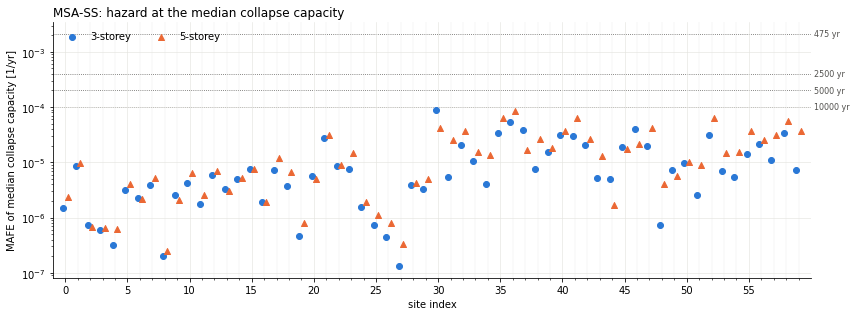

In [5]:
# ---- style ---------------------------------------------------------------------
# One colour AND one marker shape per structure height, so the two stay
# distinguishable in greyscale and for colour-blind readers.
STOREY_STYLE = {
    3: dict(color="#2a78d6", marker="o", label="3-storey"),
    5: dict(color="#eb6834", marker="^", label="5-storey"),
}
X_NUDGE = {3: -0.18, 5: +0.18}      # horizontal offset from the site index
INK2, GRID = "#52514e", "#e4e3df"   # secondary text/lines, gridlines


def plot_mafe_by_site(df, arm, arm_label, ax):
    """Scatter of the MAFE at each structure's median collapse capacity, vs site index."""
    # ---- the data: one scatter call per structure height ------------------------
    for n_storeys, style in STOREY_STYLE.items():
        rows = df[df["n_storeys"] == n_storeys]
        ax.scatter(rows["site"] + X_NUDGE[n_storeys], rows[f"{arm}_mafe"],
                   marker=style["marker"], s=36, color=style["color"], zorder=3,
                   label=style["label"])

    # ---- reference return periods ---------------------------------------------
    for rtp in REF_RTPS:
        ax.axhline(1.0 / rtp, color=INK2, ls=":", lw=0.8, zorder=1)
        # label just outside the right edge of the axes, level with its line
        ax.annotate(f"{rtp} yr", (1.0, 1.0 / rtp), xycoords=("axes fraction", "data"),
                    xytext=(3, 0), textcoords="offset points",
                    va="center", ha="left", fontsize=8, color=INK2)

    # ---- axes -------------------------------------------------------------------
    ax.set_yscale("log")
    ax.set_xlim(-1, N_SITES)
    ax.set_xticks(range(0, N_SITES, 5))
    ax.set_xticks(range(N_SITES), minor=True)      # a faint gridline at every site
    ax.set_xlabel("site index")
    ax.set_ylabel("MAFE of median collapse capacity [1/yr]")
    ax.set_title(f"{arm_label}: hazard at the median collapse capacity", loc="left")
    ax.grid(True, which="major", color=GRID, lw=0.6)
    ax.grid(True, which="minor", axis="x", color=GRID, lw=0.3)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

    ax.legend(loc="upper left", frameon=False, ncol=2)
    return ax


fig, ax = plt.subplots(figsize=(12, 4.5))
plot_mafe_by_site(capacity, "msa_ss", "MSA-SS", ax)
fig.tight_layout()
# facecolor="w": opaque white background in any viewer (project convention)
fig.savefig(OUT_DIR / "mafe_of_median_msa_ss_by_site.png", dpi=200,
            bbox_inches="tight", facecolor="w")
plt.show()